# Biomarker Name Standardization: Embedding Model Benchmark

**Task.** The same biomarker appears under different names in different lab reports ("HDL-C direct", "good cholesterol", "HDL Cholesterol"). Given a raw name, which entry of a canonical biomarker list does it refer to, or is it not a biomarker at all (a panel name, a patient field)?

**What this notebook does**
1. Embeds 97 raw names and 46 canonical biomarkers with five embedding models.
2. Adds three cheap **non-neural baselines** (fuzzy string matching, character TF-IDF), which any embedding model must beat to be worth running.
3. Scores everything with the original protocol **and** with separate matching and rejection metrics.
4. Draws the charts and error analysis needed to see *why* models win or lose.

| Model | Hugging Face ID | Pooling |
|---|---|---|
| SapBERT | `cambridgeltl/SapBERT-from-PubMedBERT-fulltext` | [CLS] (as recommended by its authors) |
| MedEmbed-small | `abhinand/MedEmbed-small-v0.1` | sentence-transformers |
| MedEmbed-large | `abhinand/MedEmbed-large-v0.1` | sentence-transformers |
| EmbeddingGemma-300M | `google/embeddinggemma-300m` | sentence-transformers (gated: accept the terms on Hugging Face and log in) |
| BioBERT v1.2 | `dmis-lab/biobert-base-cased-v1.2` | mean over tokens |

**Run it:** Colab or Kaggle with a GPU is fine, but the whole job is small and also runs on CPU in a few minutes. If a model fails to load (for example the gated Gemma model), it is skipped and everything else still runs.

## 0. Setup

In [1]:
# @title Install dependencies
!pip install -q -U sentence-transformers transformers rapidfuzz scikit-learn seaborn pandas scipy matplotlib tqdm

In [2]:
# @title Imports, plotting style, output folders
import os, gc, json, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction.text import TfidfVectorizer
from rapidfuzz import fuzz, process

warnings.filterwarnings("ignore")
RESULTS_DIR = "results"
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 13, "axes.spines.top": False,
                     "axes.spines.right": False})
C_GOOD, C_BAD, C_WARN, C_NEUTRAL = "#2a9d8f", "#e76f51", "#e9c46a", "#8d99ae"

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name + ".png"))

## 1. The test set

`canonical_biomarkers` is the target list. `answer_key` maps every raw name to its correct canonical name, or to `None` when it should be **rejected**: panel names ("CMP", "Lipid Panel") and non-biomarker report fields ("Patient Name", "Lab Address").

> Honest caveat: this answer key was written and edited by one person while testing, and some labels are debatable (for example "FT4 index" is a calculated index, not the free-T4 measurement itself). Treat results as evidence on *this* set, not as a general accuracy figure.

In [3]:
# @title The biomarker list and the answer key
canonical_biomarkers = [
    "High-Density Lipoprotein Cholesterol (HDL-C)", "Low-Density Lipoprotein Cholesterol (LDL-C)",
    "Triglycerides", "Apolipoprotein B (ApoB)", "Lipoprotein(a) (Lp(a))",
    "Homocysteine", "C-Reactive Protein, High-Sensitivity (hs-CRP)",
    "Thyroid-Stimulating Hormone (TSH)", "Thyroxine (T4), Free", "Triiodothyronine (T3), Free",
    "Thyroid Peroxidase Antibodies (TPOAb)", "Dehydroepiandrosterone Sulfate (DHEA-S)",
    "Sex Hormone-Binding Globulin (SHBG)", "Testosterone, Total", "Luteinizing Hormone (LH)",
    "Follicle-Stimulating Hormone (FSH)", "Prostate-Specific Antigen (PSA), Total",
    "Gamma-Glutamyl Transferase (GGT)", "Alanine Aminotransferase (ALT)",
    "Aspartate Aminotransferase (AST)", "Alkaline Phosphatase (ALP)", "Bilirubin, Total",
    "Albumin", "Creatinine", "Blood Urea Nitrogen (BUN)", "Estimated Glomerular Filtration Rate (eGFR)",
    "Creatine Kinase (CK)", "Uric Acid", "Insulin-like Growth Factor 1 (IGF-1)",
    "Insulin", "Hemoglobin A1c (HbA1c)", "25-Hydroxyvitamin D", "Vitamin B12",
    "White Blood Cell Count (WBC)", "Red Blood Cell Count (RBC)", "Hemoglobin (Hgb)",
    "Hematocrit (Hct)", "Platelet Count (PLT)", "Mean Corpuscular Volume (MCV)",
    "Iron, Total", "Total Iron-Binding Capacity (TIBC)", "Transferrin Saturation",
    "Ferritin", "Sodium", "Potassium", "Chloride"
]

# Each raw name maps to its one correct canonical name, or to None when it should be rejected.
answer_key = {
    "HDL Cholesterol": "High-Density Lipoprotein Cholesterol (HDL-C)",
    "hdl-c direct": "High-Density Lipoprotein Cholesterol (HDL-C)",
    "good cholesterol": "High-Density Lipoprotein Cholesterol (HDL-C)",
    "LDL, Calculated": "Low-Density Lipoprotein Cholesterol (LDL-C)",
    "ldl direct measurement": "Low-Density Lipoprotein Cholesterol (LDL-C)",
    "bad cholesterol": "Low-Density Lipoprotein Cholesterol (LDL-C)",
    "Trigs": "Triglycerides",
    "triglyceride panel": "Triglycerides",
    "Apo B-100": "Apolipoprotein B (ApoB)",
    "Apolipo B": "Apolipoprotein B (ApoB)",
    "Lp(a) particle number": "Lipoprotein(a) (Lp(a))",
    "Lipoprotein a": "Lipoprotein(a) (Lp(a))",
    "HCY, Plasma": "Homocysteine",
    "Homocystine": "Homocysteine",
    "hsCRP": "C-Reactive Protein, High-Sensitivity (hs-CRP)",
    "C Reactive Protein (Cardiac)": "C-Reactive Protein, High-Sensitivity (hs-CRP)",
    "CRP High Sensitivity": "C-Reactive Protein, High-Sensitivity (hs-CRP)",
    "Free T4": "Thyroxine (T4), Free",
    "FT4 index": "Thyroxine (T4), Free",
    "Thyroxine, Free, Direct": "Thyroxine (T4), Free",
    "Free T3": "Triiodothyronine (T3), Free",
    "FT3": "Triiodothyronine (T3), Free",
    "Total Triiodothyronine, Free": "Triiodothyronine (T3), Free",
    "Anti-TPO": "Thyroid Peroxidase Antibodies (TPOAb)",
    "Thyroid Peroxidase Ab": "Thyroid Peroxidase Antibodies (TPOAb)",
    "TPO Antibodies": "Thyroid Peroxidase Antibodies (TPOAb)",
    "DHEA Sulfate": "Dehydroepiandrosterone Sulfate (DHEA-S)",
    "DHEAS": "Dehydroepiandrosterone Sulfate (DHEA-S)",
    "SHBG, serum": "Sex Hormone-Binding Globulin (SHBG)",
    "Sex Hormone BG": "Sex Hormone-Binding Globulin (SHBG)",
    "Testosterone, T": "Testosterone, Total",
    "Total Testosterone": "Testosterone, Total",
    "LH, Serum": "Luteinizing Hormone (LH)",
    "Luteinising Hormone": "Luteinizing Hormone (LH)",
    "FSH Hormone": "Follicle-Stimulating Hormone (FSH)",
    "Follicular Stimulating Hormone": "Follicle-Stimulating Hormone (FSH)",
    "GGT, serum": "Gamma-Glutamyl Transferase (GGT)",
    "Gamma-Glutamyltranspeptidase": "Gamma-Glutamyl Transferase (GGT)",
    "ALT (SGPT)": "Alanine Aminotransferase (ALT)",
    "Alanine Transaminase": "Alanine Aminotransferase (ALT)",
    "Serum Glutamic-Pyruvic Transaminase": "Alanine Aminotransferase (ALT)",  # Known failure case
    "AST (SGOT)": "Aspartate Aminotransferase (AST)",
    "Aspartate Transaminase": "Aspartate Aminotransferase (AST)",
    "Serum Glutamic-Oxaloacetic Transaminase": "Aspartate Aminotransferase (AST)",
    "CK, Total": "Creatine Kinase (CK)",
    "Creatinine Kinase": "Creatine Kinase (CK)",
    "Urate": "Uric Acid",
    "Serum Uric Acid": "Uric Acid",
    "IGF-1 by LC/MS": "Insulin-like Growth Factor 1 (IGF-1)",
    "Somatomedin C": "Insulin-like Growth Factor 1 (IGF-1)",
    "Vitamin D, 25-Hydroxy": "25-Hydroxyvitamin D",
    "25-OH-D": "25-Hydroxyvitamin D",
    "Creatinine, Serum": "Creatinine",
    "BUN": "Blood Urea Nitrogen (BUN)",
    "Urea Nitrogen, Blood": "Blood Urea Nitrogen (BUN)",
    "GFR, Estimated": "Estimated Glomerular Filtration Rate (eGFR)",
    "Glomerular Filtration Rate, Est.": "Estimated Glomerular Filtration Rate (eGFR)",
    "ALK Phos": "Alkaline Phosphatase (ALP)",
    "Alkaline Phos.": "Alkaline Phosphatase (ALP)",
    "Bilirubin Total": "Bilirubin, Total",
    "Total Bilirubin": "Bilirubin, Total",
    "ALB": "Albumin",
    "WBC Count": "White Blood Cell Count (WBC)",
    "Leukocytes": "White Blood Cell Count (WBC)",
    "RBC": "Red Blood Cell Count (RBC)",
    "Erythrocytes": "Red Blood Cell Count (RBC)",
    "HGB": "Hemoglobin (Hgb)",
    "Haemoglobin": "Hemoglobin (Hgb)",
    "HCT": "Hematocrit (Hct)",
    "Packed Cell Volume (PCV)": "Hematocrit (Hct)",
    "Platelets": "Platelet Count (PLT)",
    "Thrombocytes": "Platelet Count (PLT)",
    "MCV": "Mean Corpuscular Volume (MCV)",
    "Serum Iron": "Iron, Total",  # Known failure case
    "TIBC": "Total Iron-Binding Capacity (TIBC)",
    "Iron Binding Capacity, Total": "Total Iron-Binding Capacity (TIBC)",
    "Transferrin % Saturation": "Transferrin Saturation",
    "TSAT": "Transferrin Saturation",  # Known failure case
    "Ferritin, Serum": "Ferritin",
    "PSA Total": "Prostate-Specific Antigen (PSA), Total",
    "Prostate Specific Ag": "Prostate-Specific Antigen (PSA), Total",
    "Insulin, Fasting": "Insulin",
    "Na+": "Sodium",
    "K+": "Potassium",
    "Cl-": "Chloride",
    "Sodium, Plasma": "Sodium",
    "Potassium, Serum": "Potassium",
    # Panel Names (Should be rejected)
    "Complete Blood Count": None,
    "CBC w/ Differential": None,
    "Comprehensive Metabolic Panel": None,
    "CMP": None,
    "Lipid Panel": None,
    # Deliberate Negative Cases (Should be rejected)
    "Blood Pressure": None,
    "Patient Name": None,
    "Date of Birth": None,
    "Lab Address": None,
    "Fasting Status: Yes": None
}

In [4]:
# @title Dataset summary and item tags
PANELS = {"Complete Blood Count", "CBC w/ Differential", "Comprehensive Metabolic Panel", "CMP", "Lipid Panel"}

def tag_item(name, gold):
    # Rough heuristic tags, used only for the per-type chart.
    if gold is None:
        return "Panel name (reject)" if name in PANELS else "Non-biomarker (reject)"
    compact = name.replace(" ", "")
    if len(compact) <= 6 or name.isupper():
        return "Short abbreviation"
    if name.lower() in {"good cholesterol", "bad cholesterol"}:
        return "Lay term"
    return "Long-form synonym or variant"

items = pd.DataFrame({"item": list(answer_key), "gold": list(answer_key.values())})
items["tag"] = [tag_item(n, answer_key[n]) for n in items["item"]]
items["is_positive"] = items["gold"].notna()
print(f"{len(canonical_biomarkers)} canonical biomarkers | {len(items)} raw names "
      f"({items.is_positive.sum()} to match, {(~items.is_positive).sum()} to reject)")
display(items.groupby("tag").size().rename("n").to_frame())

46 canonical biomarkers | 97 raw names (87 to match, 10 to reject)


,n
tag,
Lay term,2
Long-form synonym or variant,64
Non-biomarker (reject),5
Panel name (reject),5
Short abbreviation,21


## 2. Models and baselines

Every method produces the same thing: a **similarity matrix** `S` of shape (97 raw names × 46 canonical names). Everything after this section works from those matrices, so scoring is identical for every method.

The three baselines need no model download:
- **Fuzzy (WRatio)** and **Fuzzy (token set)**: classic string similarity from `rapidfuzz`.
- **TF-IDF char n-gram**: cosine similarity over 2-4 character n-grams.

In [5]:
# @title Model registry
MODELS = [
    {"name": "SapBERT",             "hf_id": "cambridgeltl/SapBERT-from-PubMedBERT-fulltext", "kind": "hf", "pooling": "cls"},
    {"name": "MedEmbed-small",      "hf_id": "abhinand/MedEmbed-small-v0.1",                  "kind": "st"},
    {"name": "MedEmbed-large",      "hf_id": "abhinand/MedEmbed-large-v0.1",                  "kind": "st"},
    {"name": "EmbeddingGemma-300M", "hf_id": "google/embeddinggemma-300m",                    "kind": "st"},
    {"name": "BioBERT-v1.2",        "hf_id": "dmis-lab/biobert-base-cased-v1.2",              "kind": "hf", "pooling": "mean"},
]
raw_names = items["item"].tolist()

In [6]:
# @title Embedding helpers (same pooling as the original experiment)
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def l2norm(x):
    return x / np.clip(np.linalg.norm(x, axis=1, keepdims=True), 1e-12, None)

def embed_hf(texts, model_id, pooling, batch_size=32):
    from transformers import AutoTokenizer, AutoModel
    tok = AutoTokenizer.from_pretrained(model_id)
    mdl = AutoModel.from_pretrained(model_id).to(DEVICE).eval()
    outs = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], return_tensors="pt", truncation=True, padding=True).to(DEVICE)
        with torch.no_grad():
            h = mdl(**enc).last_hidden_state
        if pooling == "cls":
            v = h[:, 0, :]
        else:  # mean over real (non-padding) tokens, as when encoding one text at a time
            m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)
            v = (h * m).sum(1) / m.sum(1)
        outs.append(v.float().cpu().numpy())
    del mdl
    return np.vstack(outs)

def embed_st(texts, model_id, batch_size=32):
    from sentence_transformers import SentenceTransformer
    mdl = SentenceTransformer(model_id, trust_remote_code=True, device=DEVICE)
    v = mdl.encode(texts, batch_size=batch_size, convert_to_numpy=True, show_progress_bar=False)
    del mdl
    return v

def similarity_matrix(spec):
    texts = raw_names + canonical_biomarkers
    if spec["kind"] == "hf":
        E = embed_hf(texts, spec["hf_id"], spec["pooling"])
    else:
        E = embed_st(texts, spec["hf_id"])
    E = l2norm(E)
    return E[:len(raw_names)] @ E[len(raw_names):].T

In [7]:
# @title Run the models (a model that fails to load is skipped, not fatal)
sims, failed = {}, {}
for spec in MODELS:
    print(f"-> {spec['name']}  ({spec['hf_id']})")
    try:
        sims[spec["name"]] = similarity_matrix(spec)
        print("   done")
    except Exception as e:
        failed[spec["name"]] = f"{type(e).__name__}: {str(e)[:160]}"
        print("   SKIPPED:", failed[spec["name"]])
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

-> SapBERT  (cambridgeltl/SapBERT-from-PubMedBERT-fulltext)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

   done
-> MedEmbed-small  (abhinand/MedEmbed-small-v0.1)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

   done
-> MedEmbed-large  (abhinand/MedEmbed-large-v0.1)


...

3_Dense/model.safetensors: downloading bytes:           |  0.00B            

   done
-> BioBERT-v1.2  (dmis-lab/biobert-base-cased-v1.2)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


   done


In [8]:
# @title Run the non-neural baselines
def tfidf_sim(a, b, ngram=(2, 4)):
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=ngram, lowercase=True).fit(a + b)
    return (vec.transform(a) @ vec.transform(b).T).toarray()

lower_raw = [r.lower() for r in raw_names]
lower_can = [c.lower() for c in canonical_biomarkers]
BASELINES = {
    "Fuzzy (WRatio)":     process.cdist(lower_raw, lower_can, scorer=fuzz.WRatio) / 100,
    "Fuzzy (token set)":  process.cdist(lower_raw, lower_can, scorer=fuzz.token_set_ratio) / 100,
    "TF-IDF char n-gram": tfidf_sim(lower_raw, lower_can),
}
sims.update(BASELINES)
BASELINE_NAMES = list(BASELINES)
print("Methods scored:", list(sims))

Methods scored: ['SapBERT', 'MedEmbed-small', 'MedEmbed-large', 'EmbeddingGemma-300M', 'BioBERT-v1.2', 'Fuzzy (WRatio)', 'Fuzzy (token set)', 'TF-IDF char n-gram']


## 3. Scoring

Two views, both reported:

- **Original protocol** (kept so results stay comparable with the first version of this experiment): a name to match is correct if the top-1 canonical name is right; a name to reject is correct if its best similarity is **below 0.60**.
- **Separated metrics**: *matching accuracy* on the 87 names that should match (no threshold involved), *rejection accuracy* at 0.60 on the 10 that should be rejected, and **AUROC**: how well the best-match score alone separates real biomarkers from non-biomarkers. AUROC does not depend on any threshold, so it is the fairest way to compare models whose similarity scores live on different scales.

In [9]:
# @title Build the per-item results table and the scoreboard
THRESHOLD = 0.60

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (c - h, c + h)

def build_rows(sims):
    rows = []
    for name, S in sims.items():
        top_idx, top_score = S.argmax(1), S.max(1)
        for i, row in items.iterrows():
            gold = None if pd.isna(row["gold"]) else row["gold"]
            pred = canonical_biomarkers[top_idx[i]]
            if gold is None:
                outcome = "Correct rejection" if top_score[i] < THRESHOLD else "False accept"
                correct, gold_rank = top_score[i] < THRESHOLD, np.nan
            else:
                correct = pred == gold
                outcome = "Correct match" if correct else "Wrong match"
                gold_rank = int((S[i] > S[i, canonical_biomarkers.index(gold)]).sum()) + 1
            rows.append(dict(model=name, item=row["item"], tag=row["tag"], gold=gold, pred=pred,
                             top_score=float(top_score[i]), outcome=outcome, correct=bool(correct),
                             gold_rank=gold_rank))
    return pd.DataFrame(rows)

df = build_rows(sims)

In [10]:
# @title Scoreboard
def scoreboard(df):
    out = []
    for m, g in df.groupby("model", sort=False):
        pos, neg = g[g.gold.notna()], g[g.gold.isna()]
        y = g.gold.notna().astype(int)
        k, n = int(g.correct.sum()), len(g)
        lo, hi = wilson(k, n)
        mk, mn = int(pos.correct.sum()), len(pos)
        mlo, mhi = wilson(mk, mn)
        r3 = (pos.gold_rank <= 3).mean() if pos.gold_rank.notna().any() else np.nan
        out.append(dict(model=m, kind="Baseline" if m in BASELINE_NAMES else "Embedding model",
                        original_acc=k / n, orig_lo=lo, orig_hi=hi, correct=k, total=n,
                        match_acc=mk / mn, match_lo=mlo, match_hi=mhi, recall_at_3=r3,
                        reject_acc=neg.correct.mean(), auroc=roc_auc_score(y, g.top_score)))
    return pd.DataFrame(out).sort_values("original_acc", ascending=False).reset_index(drop=True)

sb = scoreboard(df)
show = sb[["model", "kind", "original_acc", "match_acc", "recall_at_3", "reject_acc", "auroc"]].copy()
for c in ["original_acc", "match_acc", "recall_at_3", "reject_acc"]:
    show[c] = (show[c] * 100).round(1)
show["auroc"] = show["auroc"].round(3)
show.columns = ["Method", "Type", "Original protocol %", "Matching % (n=87)", "Recall@3 %", "Rejection % (n=10)", "AUROC"]
display(show)
if failed:
    print("Skipped models:", failed)

,Method,Type,Original protocol %,Matching % (n=87),Recall@3 %,Rejection % (n=10),AUROC
0,SapBERT,Embedding model,95.9,96.6,100.0,90.0,0.972
1,MedEmbed-small,Embedding model,80.4,89.7,92.0,0.0,0.923
2,MedEmbed-large,Embedding model,79.4,87.4,95.4,10.0,0.936
3,EmbeddingGemma-300M,Embedding model,79.4,79.3,92.0,80.0,0.907
4,TF-IDF char n-gram,Baseline,77.3,74.7,88.5,100.0,0.843
5,Fuzzy (WRatio),Baseline,56.7,55.2,78.2,70.0,0.793
6,Fuzzy (token set),Baseline,55.7,51.7,66.7,90.0,0.740
7,BioBERT-v1.2,Embedding model,48.5,54.0,66.7,0.0,0.823


## 4. Charts

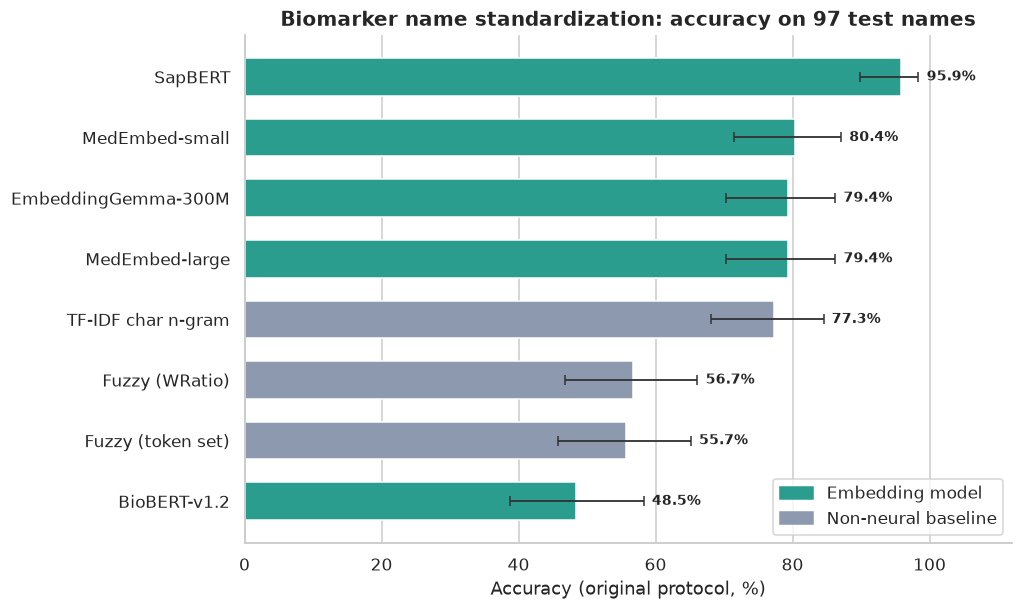

In [11]:
# @title Chart 1: leaderboard with 95% confidence intervals
order = sb.sort_values("original_acc")
fig, ax = plt.subplots(figsize=(9, 0.6 * len(order) + 1.2))
colors = [C_NEUTRAL if k == "Baseline" else C_GOOD for k in order.kind]
ax.barh(order.model, order.original_acc * 100, color=colors, height=0.62)
ax.errorbar(order.original_acc * 100, range(len(order)),
            xerr=[(order.original_acc - order.orig_lo) * 100, (order.orig_hi - order.original_acc) * 100],
            fmt="none", ecolor="#333", capsize=3, lw=1.2)
for y, (v, hi) in enumerate(zip(order.original_acc * 100, order.orig_hi * 100)):
    ax.text(hi + 1.2, y, f"{v:.1f}%", va="center", fontsize=9, fontweight="bold")
ax.set_xlim(0, 112); ax.set_xticks(range(0, 101, 20)); ax.grid(axis="y", visible=False)
ax.set_xlabel("Accuracy (original protocol, %)")
ax.set_title("Biomarker name standardization: accuracy on 97 test names")
ax.legend(handles=[mpl.patches.Patch(color=C_GOOD, label="Embedding model"),
                   mpl.patches.Patch(color=C_NEUTRAL, label="Non-neural baseline")], loc="lower right")
savefig("01_leaderboard"); plt.show()

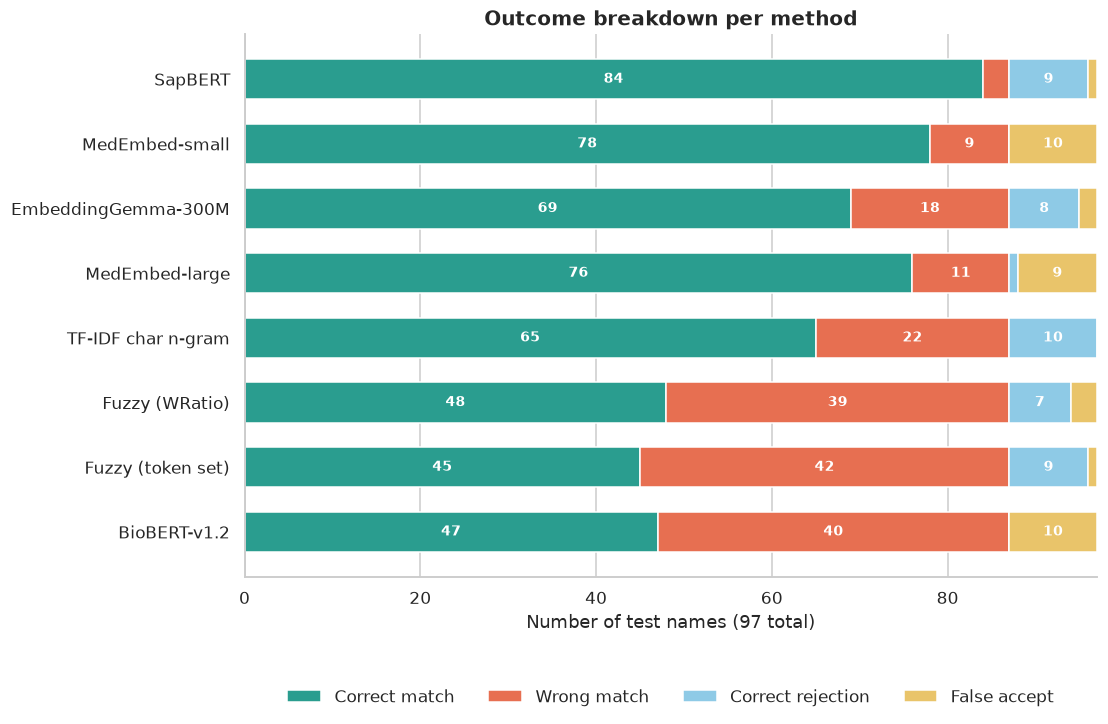

In [12]:
# @title Chart 2: where does each method lose points?
cats = ["Correct match", "Wrong match", "Correct rejection", "False accept"]
cols = [C_GOOD, C_BAD, "#8ecae6", C_WARN]
ct = (df.groupby(["model", "outcome"]).size().unstack(fill_value=0).reindex(columns=cats, fill_value=0))
ct = ct.loc[sb.sort_values("original_acc").model]
fig, ax = plt.subplots(figsize=(10, 0.6 * len(ct) + 1.6))
left = np.zeros(len(ct))
for c, col in zip(cats, cols):
    ax.barh(ct.index, ct[c], left=left, color=col, label=c, height=0.62)
    for y, (l, v) in enumerate(zip(left, ct[c])):
        if v >= 4: ax.text(l + v / 2, y, int(v), ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += ct[c].values
ax.set_xlabel("Number of test names (97 total)"); ax.set_title("Outcome breakdown per method")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
savefig("02_outcome_breakdown"); plt.show()

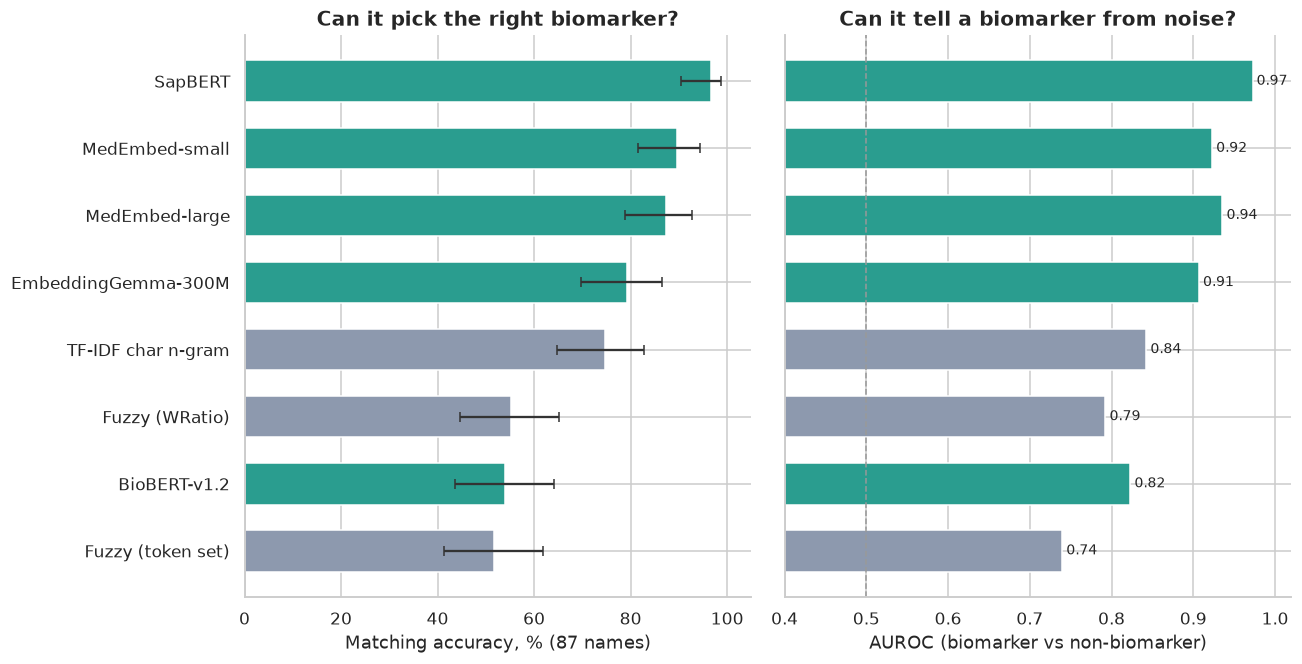

In [13]:
# @title Chart 3: matching accuracy vs rejection ability (threshold-free AUROC)
fig, axes = plt.subplots(1, 2, figsize=(12, 0.55 * len(sb) + 1.8), sharey=True)
o = sb.sort_values("match_acc")
axes[0].barh(o.model, o.match_acc * 100, color=[C_NEUTRAL if k == "Baseline" else C_GOOD for k in o.kind], height=0.62)
axes[0].errorbar(o.match_acc * 100, range(len(o)),
                 xerr=[(o.match_acc - o.match_lo) * 100, (o.match_hi - o.match_acc) * 100], fmt="none", ecolor="#333", capsize=3)
axes[0].set_xlim(0, 105); axes[0].set_xlabel("Matching accuracy, % (87 names)"); axes[0].set_title("Can it pick the right biomarker?")
axes[1].barh(o.model, o.auroc, color=[C_NEUTRAL if k == "Baseline" else C_GOOD for k in o.kind], height=0.62)
axes[1].axvline(0.5, color="#999", ls="--", lw=1); axes[1].set_xlim(0.4, 1.02)
axes[1].set_xlabel("AUROC (biomarker vs non-biomarker)"); axes[1].set_title("Can it tell a biomarker from noise?")
for y, v in enumerate(o.auroc): axes[1].text(v + 0.005, y, f"{v:.2f}", va="center", fontsize=9)
plt.tight_layout(); savefig("03_matching_vs_rejection"); plt.show()

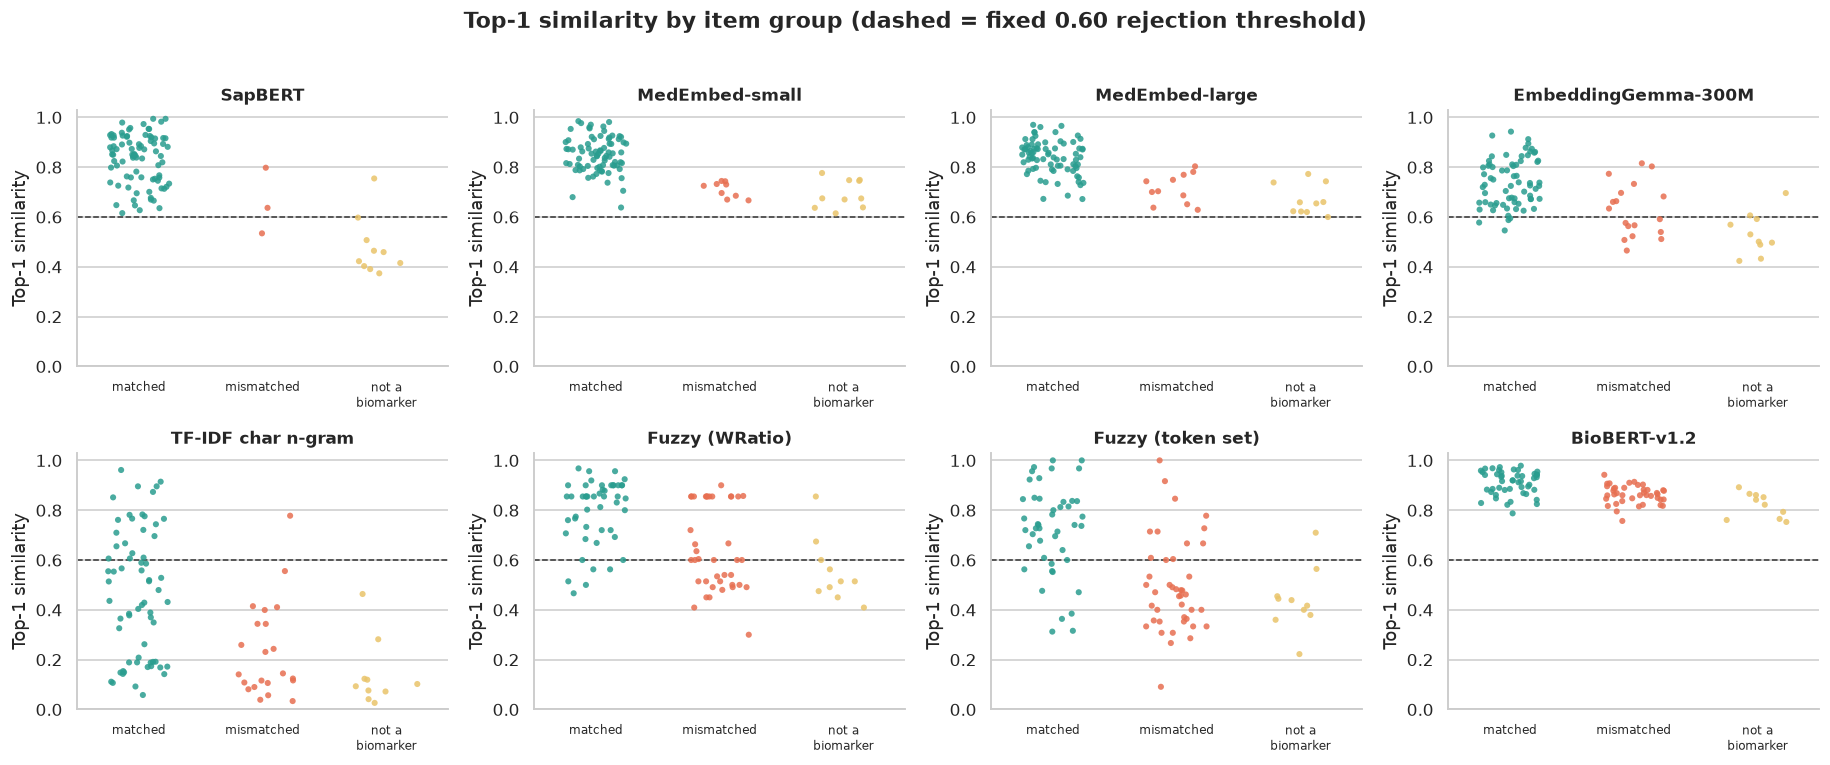

In [14]:
# @title Chart 4: similarity score distributions and the fixed 0.60 threshold
models_ord = sb.model.tolist()
n = len(models_ord); ncol = 4; nrow = math.ceil(n / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.4 * nrow), squeeze=False)
pal = {"Biomarker, matched": C_GOOD, "Biomarker, mismatched": C_BAD, "Not a biomarker": C_WARN}
def grp(r):
    if pd.isna(r.gold): return "Not a biomarker"
    return "Biomarker, matched" if r.correct else "Biomarker, mismatched"
for ax, m in zip(axes.ravel(), models_ord):
    g = df[df.model == m].copy(); g["group"] = g.apply(grp, axis=1)
    sns.stripplot(data=g, x="group", y="top_score", order=list(pal), palette=pal, size=4, jitter=0.25, ax=ax, alpha=0.85)
    ax.axhline(THRESHOLD, color="#333", ls="--", lw=1)
    ax.set_ylim(0, 1.03); ax.grid(axis="x", visible=False)
    ax.set_title(m, fontsize=11); ax.set_xlabel(""); ax.set_ylabel("Top-1 similarity")
    ax.set_xticklabels(["matched", "mismatched", "not a\nbiomarker"], fontsize=8)
for ax in axes.ravel()[n:]: ax.axis("off")
fig.suptitle("Top-1 similarity by item group (dashed = fixed 0.60 rejection threshold)", fontweight="bold", y=1.02)
plt.tight_layout(); savefig("04_score_distributions"); plt.show()

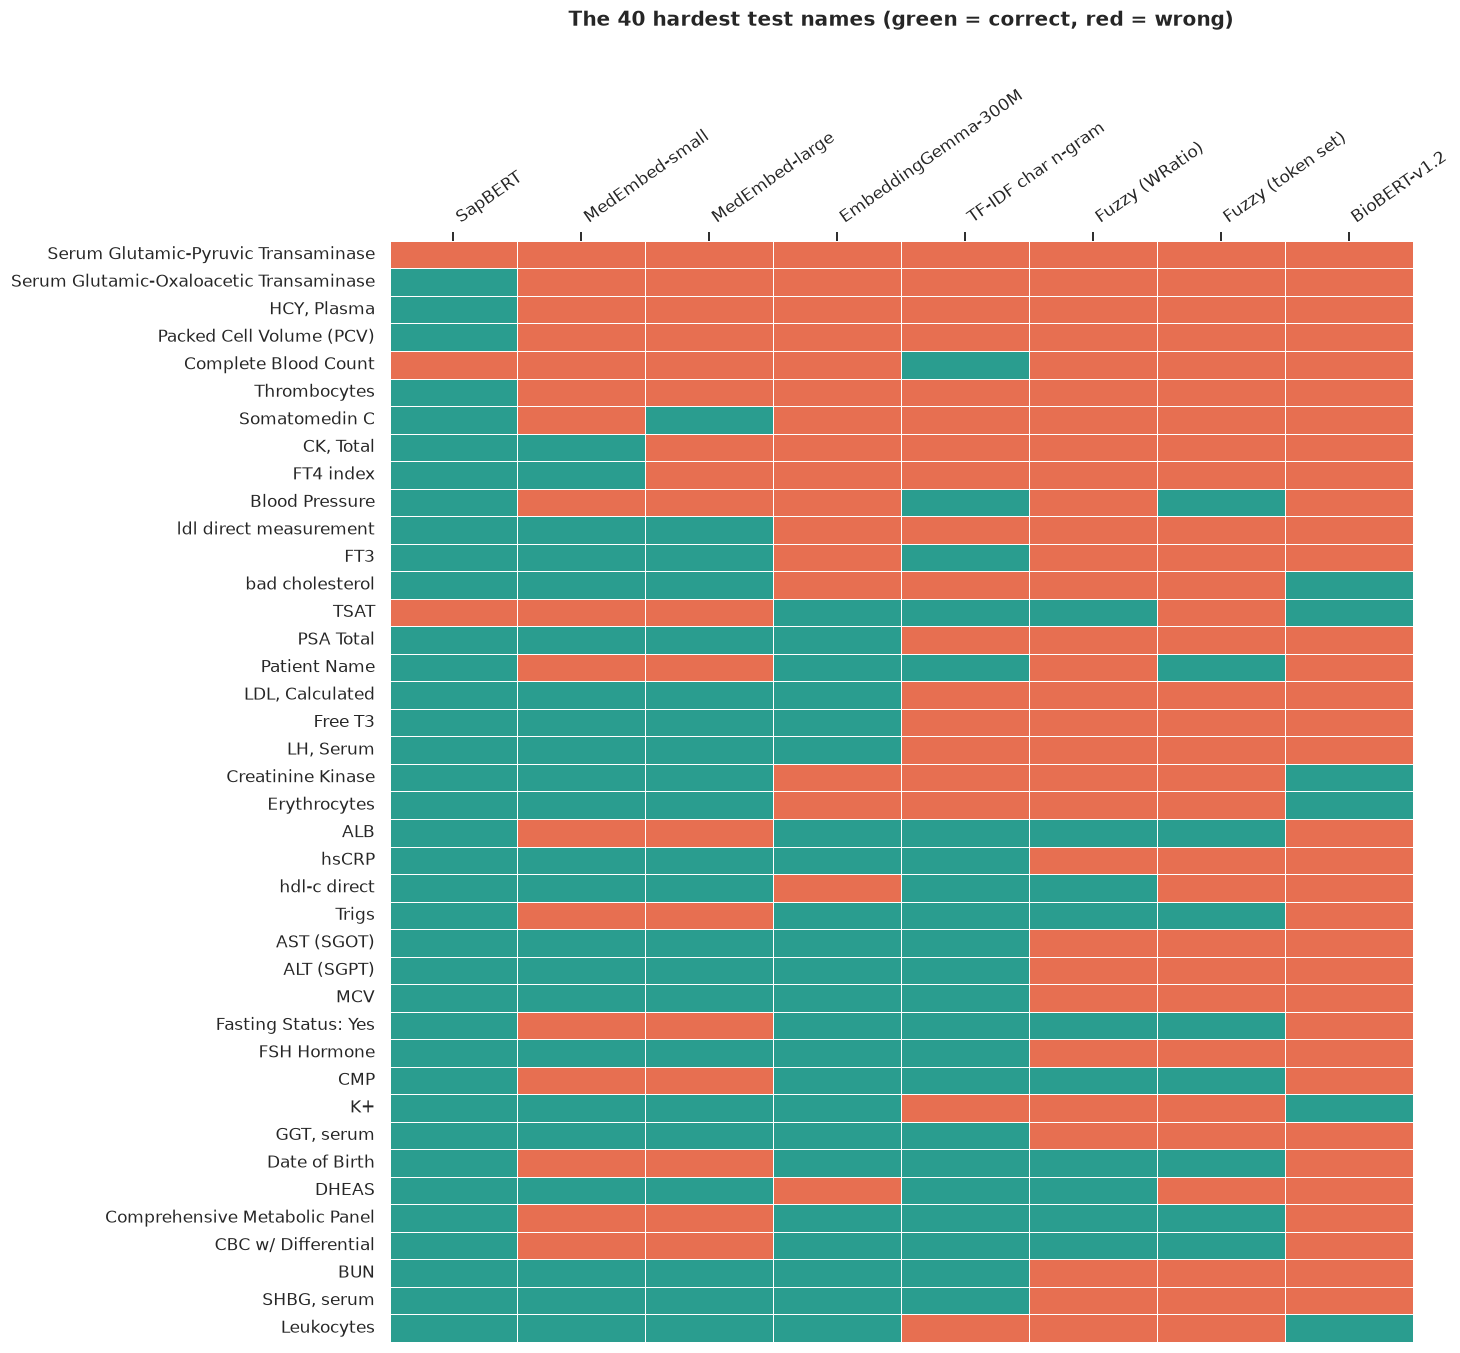

In [15]:
# @title Chart 5: which test names are hardest? (heatmap of correct / wrong)
wide = df.pivot(index="item", columns="model", values="correct")[models_ord]
wide = wide.loc[wide.sum(1) < wide.shape[1]]           # keep names at least one method got wrong
wide = wide.loc[(~wide).sum(1).sort_values(ascending=False).index].head(40)   # the 40 hardest names
fig, ax = plt.subplots(figsize=(1.0 * len(models_ord) + 4, 0.28 * len(wide) + 1.8))
sns.heatmap(wide.astype(int), cmap=mpl.colors.ListedColormap([C_BAD, C_GOOD]), cbar=False, linewidths=0.6,
            linecolor="white", ax=ax, vmin=0, vmax=1)
ax.set_xlabel(""); ax.set_ylabel(""); ax.xaxis.tick_top(); plt.setp(ax.get_xticklabels(), rotation=35, ha="left")
ax.set_title("The 40 hardest test names (green = correct, red = wrong)", pad=40)
savefig("05_hard_items_heatmap"); plt.show()

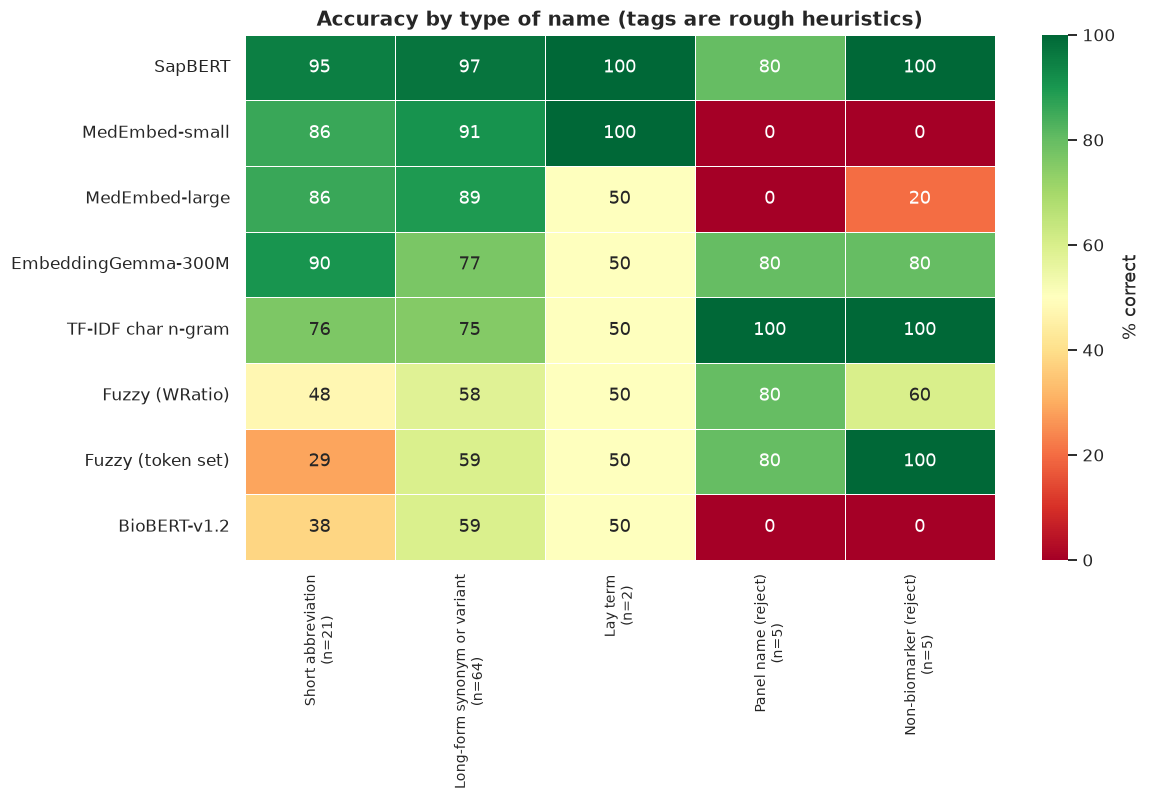

In [16]:
# @title Chart 6: accuracy by type of raw name
by_tag = df.groupby(["model", "tag"]).correct.mean().unstack() * 100
by_tag = by_tag.loc[models_ord]
tag_order = [t for t in ["Short abbreviation", "Long-form synonym or variant", "Lay term",
                         "Panel name (reject)", "Non-biomarker (reject)"] if t in by_tag.columns]
counts = items.groupby("tag").size()
fig, ax = plt.subplots(figsize=(11, 0.5 * len(by_tag) + 2.2))
sns.heatmap(by_tag[tag_order], annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100, cbar_kws={"label": "% correct"}, ax=ax, linewidths=0.5)
ax.set_xticklabels([f"{t}\n(n={counts[t]})" for t in tag_order], fontsize=9)
ax.set_ylabel(""); ax.set_xlabel(""); ax.set_title("Accuracy by type of name (tags are rough heuristics)")
savefig("06_accuracy_by_type"); plt.show()

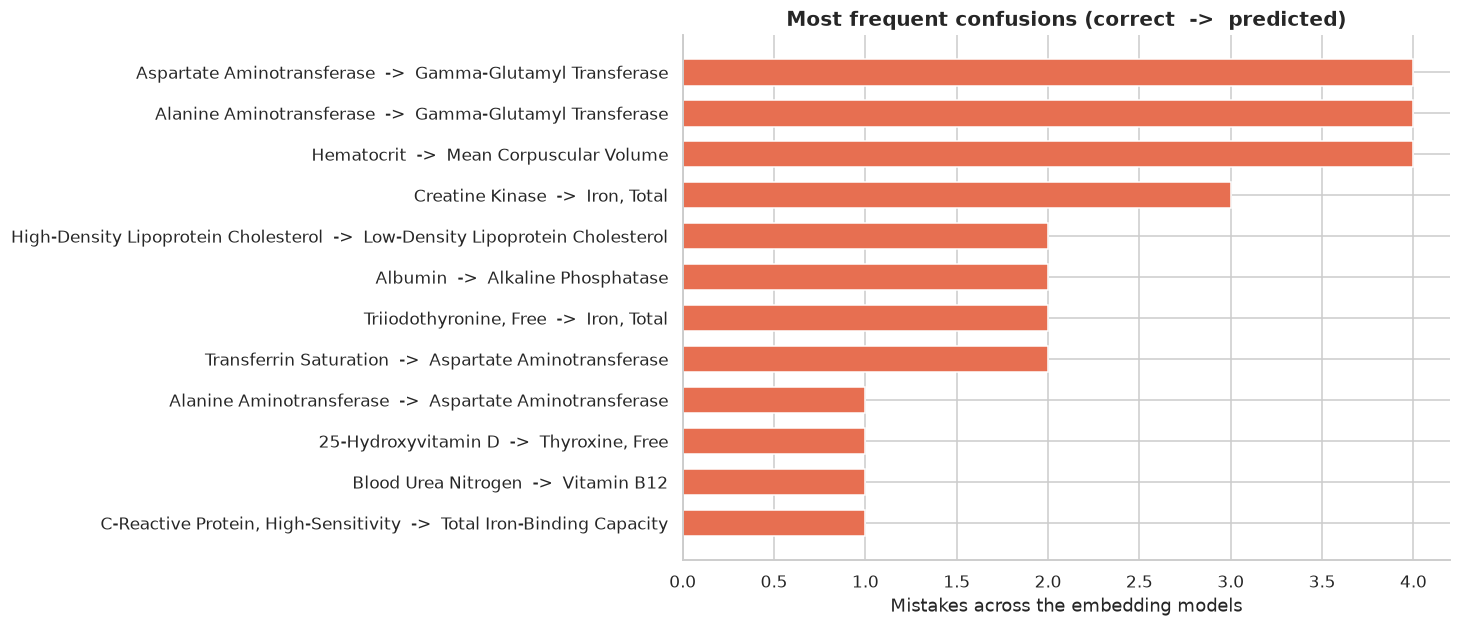

In [17]:
# @title Chart 7: most common confusions (wrong canonical name chosen)
wrong = df[(df.gold.notna()) & (~df.correct) & (~df.model.isin(BASELINE_NAMES))]
pairs = (wrong.assign(pair=lambda d: d.gold.str.replace(r"\s*\(.*\)", "", regex=True) + "  ->  " + d.pred.str.replace(r"\s*\(.*\)", "", regex=True))
         .groupby("pair").size().sort_values(ascending=False).head(12))
fig, ax = plt.subplots(figsize=(9, 0.4 * len(pairs) + 1.4))
ax.barh(pairs.index[::-1], pairs.values[::-1], color=C_BAD, height=0.65)
ax.set_xlabel("Mistakes across the embedding models"); ax.set_title("Most frequent confusions (correct  ->  predicted)")
savefig("07_top_confusions"); plt.show()

## 5. Statistics and error analysis

In [18]:
# @title Is the top model reliably better? (exact McNemar test on the original protocol)
emb = sb[sb.kind == "Embedding model"]
best = (emb if len(emb) else sb).model.iloc[0]
cb = df[df.model == best].set_index("item").correct
rows = []
for m in models_ord:
    if m == best: continue
    co = df[df.model == m].set_index("item").correct.reindex(cb.index)
    b_only, o_only = int((cb & ~co).sum()), int((~cb & co).sum())
    p = stats.binomtest(b_only, b_only + o_only, 0.5).pvalue if (b_only + o_only) else 1.0
    rows.append({"vs": m, f"{best} right, other wrong": b_only, f"other right, {best} wrong": o_only,
                 "p-value": round(p, 4), "significant (p<0.05)": p < 0.05})
display(pd.DataFrame(rows))

,vs,"SapBERT right, other wrong","other right, SapBERT wrong",p-value,significant (p<0.05)
0,MedEmbed-small,16,1,0.0003,True
1,MedEmbed-large,17,1,0.0001,True
2,EmbeddingGemma-300M,17,1,0.0001,True
3,TF-IDF char n-gram,21,3,0.0003,True
4,Fuzzy (WRatio),39,1,0.0000,True
5,Fuzzy (token set),40,1,0.0000,True
6,BioBERT-v1.2,48,2,0.0000,True


In [19]:
# @title Every mistake made by the best embedding model
e = df[(df.model == best) & (~df.correct)][["item", "gold", "pred", "top_score", "outcome"]].round(3)
display(e.reset_index(drop=True))

,item,gold,pred,top_score,outcome
0,Serum Glutamic-Pyruvic Transaminase,Alanine Aminotransferase (ALT),Aspartate Aminotransferase (AST),0.798,Wrong match
1,Serum Iron,"Iron, Total",Transferrin Saturation,0.637,Wrong match
2,TSAT,Transferrin Saturation,Aspartate Aminotransferase (AST),0.534,Wrong match
3,Complete Blood Count,NaN,White Blood Cell Count (WBC),0.754,False accept


In [20]:
# @title Save results
df.to_csv(os.path.join(RESULTS_DIR, "per_item_results.csv"), index=False)
sb.to_csv(os.path.join(RESULTS_DIR, "scoreboard.csv"), index=False)
print("Saved results/per_item_results.csv, results/scoreboard.csv and results/figures/*.png")

Saved results/per_item_results.csv, results/scoreboard.csv and results/figures/*.png


## 6. How to read the results, and what could be wrong

- **The original 0.60 threshold is not neutral.** Models place their similarity scores on different scales, so one fixed cutoff hurts some of them (see Chart 4). Use the **matching accuracy** and **AUROC** columns to compare models fairly, and treat the original-protocol column as a reproduction of the first experiment.
- **Beat the baselines first.** A model that cannot clearly beat fuzzy or character-n-gram matching is not earning its compute cost.
- **Small, single-author test set.** 97 names (87 to match, 10 to reject). The confidence intervals in Chart 1 are wide; differences of a few names between models are noise, and some answer-key labels are debatable.
- **Tuned while testing.** The answer key was edited during development and there is no held-out set, so scores are probably a little optimistic.
- **Next steps:** a held-out set of names from real lab reports, multilingual and unit-bearing names ("Glucose mg/dL"), a calibrated per-model rejection threshold chosen on a separate split, and a comparison with ontology lookups (LOINC, UMLS).